# A. DATA PREPARATION

A1. Import dataset

In [45]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns

A2. Menambahkan datasest

In [46]:
df = pd.read_csv('drug200.csv')

A3. Melihat 5 data teratas

In [47]:
df.head()

,Age,Sex,BP,Cholesterol,Na_to_K,Drug
0,23,F,HIGH,HIGH,25.355,drugY
1,47,M,LOW,HIGH,13.093,drugC
2,47,M,LOW,HIGH,10.114,drugC
3,28,F,NORMAL,HIGH,7.798,drugX
4,61,F,LOW,HIGH,18.043,drugY


A4. Melihat deskripsi data

In [48]:
df.describe()

,Age,Na_to_K
count,200.000000,200.000000
mean,44.315000,16.084485
std,16.544315,7.223956
min,15.000000,6.269000
25%,31.000000,10.445500
50%,45.000000,13.936500
75%,58.000000,19.380000
max,74.000000,38.247000


Hasil dari yang ada di atas :
- Rata-rata umur yang ada di atas ada di 44 Tahun / Paruh Baya, Hal ini mengindikasikan bahwa data di dominasi oleh kelompok usia Paruh Baya.
- Fitur Na-to_K memiliki nilai standar defiasi yang cukup besar terhadap nilai rata-rata, Hal ini mengindikasikan fitur ini dapat menjadi faktor pembeda untuk klasifikasi jenis obat.

A5. Melihat informasi data

In [49]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Age          200 non-null    int64  
 1   Sex          200 non-null    str    
 2   BP           200 non-null    str    
 3   Cholesterol  200 non-null    str    
 4   Na_to_K      200 non-null    float64
 5   Drug         200 non-null    str    
dtypes: float64(1), int64(1), str(4)
memory usage: 9.5 KB


Dari hasil di atas :
- Ada 200 baris dengan 6 kolom
- Ada tipe data float, int, dan str

A6. Melihat data kosong

In [50]:
df.isna().sum()

Age            0
Sex            0
BP             0
Cholesterol    0
Na_to_K        0
Drug           0
dtype: int64

Dari hasil di atas tidak ada data kosong

A7. Melihat duplikasi data

In [51]:
def cek_duplikat(df):
    duplicated_df = df[df.duplicated()].sum()
    index_list = duplicated_df.index.tolist()
    print ('Data yang terindikasi duplikat :')
    print (duplicated_df)
    print (f'Baris : {index_list}')

In [52]:
cek_duplikat(df)

Data yang terindikasi duplikat :
Age              0
Sex               
BP                
Cholesterol       
Na_to_K        0.0
Drug              
dtype: object
Baris : ['Age', 'Sex', 'BP', 'Cholesterol', 'Na_to_K', 'Drug']


Dari hasil di atas tidak terindikasi data duplikat

A8. Melihat isi dari kolom BP (Blood Presure)

In [53]:
df['BP'].unique()

<StringArray>
['HIGH', 'LOW', 'NORMAL']
Length: 3, dtype: str

A9. Melihat isi dari kolom Cholesterol

In [54]:
df['Cholesterol'].unique()

<StringArray>
['HIGH', 'NORMAL']
Length: 2, dtype: str

A10. Melakukan One Hot Encoding

In [55]:
# One hot encoding
df_encode = pd.get_dummies(df, columns= ['BP', 'Cholesterol'], dtype=int)

In [56]:
df_encode.head()

,Age,Sex,Na_to_K,Drug,BP_HIGH,BP_LOW,BP_NORMAL,Cholesterol_HIGH,Cholesterol_NORMAL
0,23,F,25.355,drugY,1,0,0,1,0
1,47,M,13.093,drugC,0,1,0,1,0
2,47,M,10.114,drugC,0,1,0,1,0
3,28,F,7.798,drugX,0,0,1,1,0
4,61,F,18.043,drugY,0,1,0,1,0


Kami melakukan One Hot Encoding agar dapat menggunakan model Decision Tree (Mengubahnya menjadi Binary)

A11. Melihat data dari kolom Drug

In [57]:
df_encode['Drug'].unique()

<StringArray>
['drugY', 'drugC', 'drugX', 'drugA', 'drugB']
Length: 5, dtype: str

In [58]:
df_encode['Drug'] = df['Drug'].replace({
    'drugA': '1',
    'drugB': '2',
    'drugC': '3',
    'drugX': '4',
    'drugY': '5',
})

Kami melakukan encoding fitur label menjadi numerik

A12. Melihat data dari kolom sex

In [59]:
df_encode['Sex'].unique()

<StringArray>
['F', 'M']
Length: 2, dtype: str

In [60]:
df_encode['Sex'] = df['Sex'].replace({
    'F': '1',
    'M': '2',
})

# B. EDA

B1. Menamplikan Plot distribusi Drug berdasarkan BP (Blood Presure)

<Axes: xlabel='count', ylabel='Drug'>

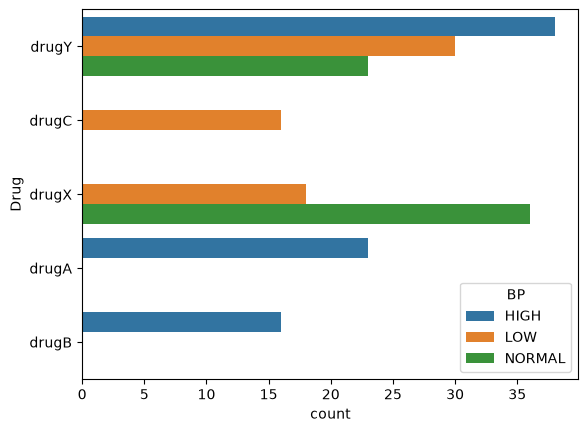

In [61]:
sns.countplot(data=df, y='Drug', hue='BP')

Berdasarkan hasil di atas:
- Drug A, B, Y Memiliki BP yang mendominasi HIGH
- Drug C Hanya memiliki BP LOW
- Drug X Memiliki BP dari LOW hingga NORMAL

B2. Menampilkan Plot Distribusi Drug berdasarkan Cholesterol

<Axes: xlabel='count', ylabel='Drug'>

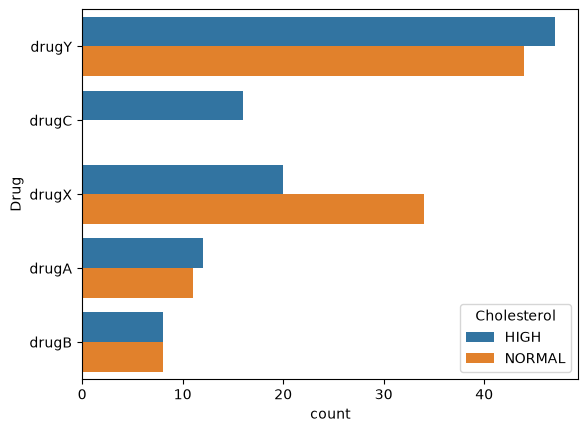

In [62]:
sns.countplot(data=df, y='Drug', hue='Cholesterol')

Berdasarkan hasil di atas:
- Drug A, B, C, Y memiliki Cholesterol yang lebih besar atau sama dibandingkan NORMAL
- Drug X Memiliki Cholesterol yang didominasi NORMAL

Pada kedua hasil plot di atas Ada pola yang mengindikasikan Bahwa kombinasi fitur BP dan Cholesterol memiliki pola yang berbeda terhadap jenis obat.

B3. Menampilkan Histogram untuk melihat distribusi data

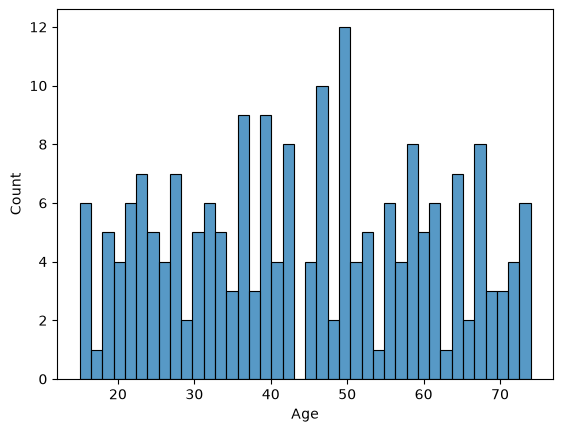

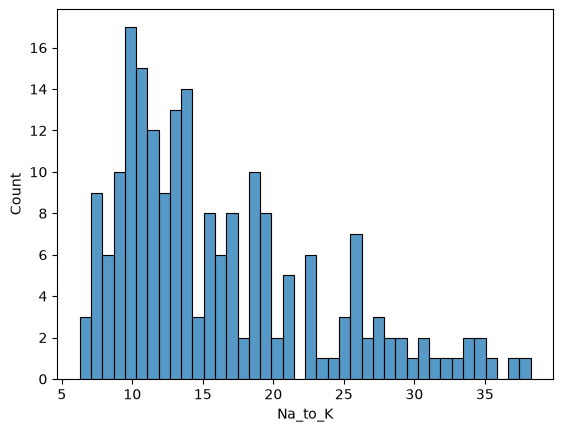

In [63]:
for i in df.select_dtypes(include=[np.number]):
    sns.histplot(df[i], bins=40)
    plt.show()

Berdasarkan hasil di atas:
- Distribusi Age relatif merata sehingga data mencakup berbagai kelompok usia.
- Distribusi kolom Na_to_K Menunjukan adanya Kemiringan ke kanan, Sehingga mengindikasikan bahwa sebagian besar data memiliki nilai relatif rendah, sementara hanya sebagian kecil data yang memiliki nilai yang lebih tinggi 
- Kedua fitur tersebut memiliki skala yang berbeda yang sebaiknya menggunakan fitur scalling untuk menyetarakan skala 2 fitur tersebut. Namun karena kami menggunakan algoritma Decision Tree, fitur scalling sudah tidak wajib di lakukan.

B4. Menampilkan boxplot untuk melihat outlier

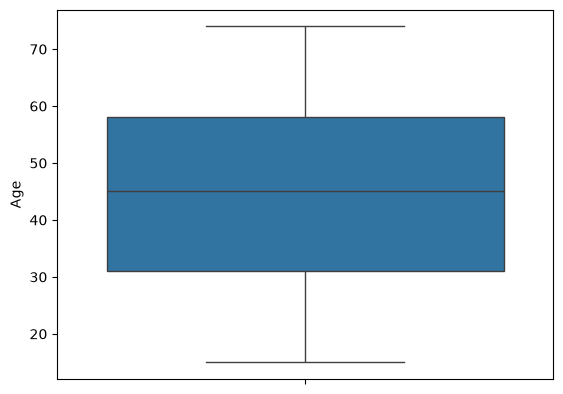

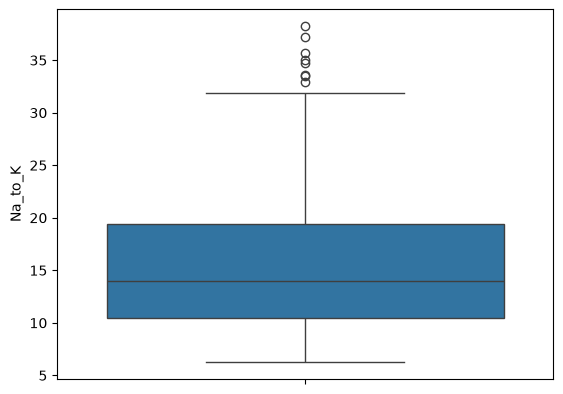

In [64]:
for i in df.select_dtypes(include=[np.number]):
    sns.boxplot(df[i])
    plt.show()

Dari hasil di atas :
- Terindikasi terdapat outlier pada fitur Na_to_K, Namun kami mengindikasikan bahwa titik-titik tersebut bukan outlier extrem sehingga kami memilih untuk tidak menangani outlier tersebut karena bisa saja titik-titik yang di anggap outlier tersebut adalah nilai yang berguna untuk klasifikasi Drug.

B5. Menampilkan distribusi kesetaraan tiap label Drug

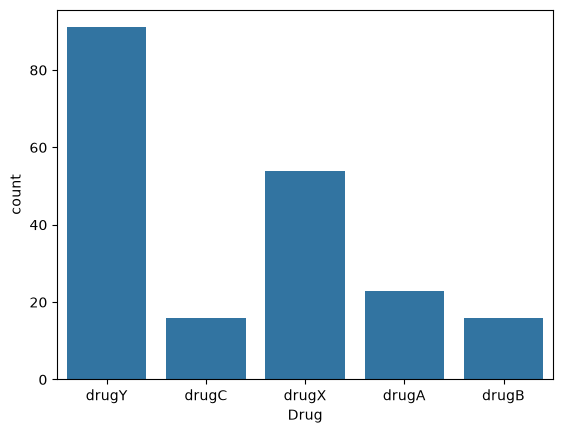

In [65]:
sns.countplot(data=df, x='Drug')
plt.show()

Berdasarkan hasil di atas kolom label memiliki ketidak seimbangan data, Hal ini dapat memengaruhi hasil klasifikasi model. Namun karena kami menggunakan algoritma Decision Tree, jumlah data setiap kelas tidak harus seimbang.

B.6 Menampilkan Pairplot

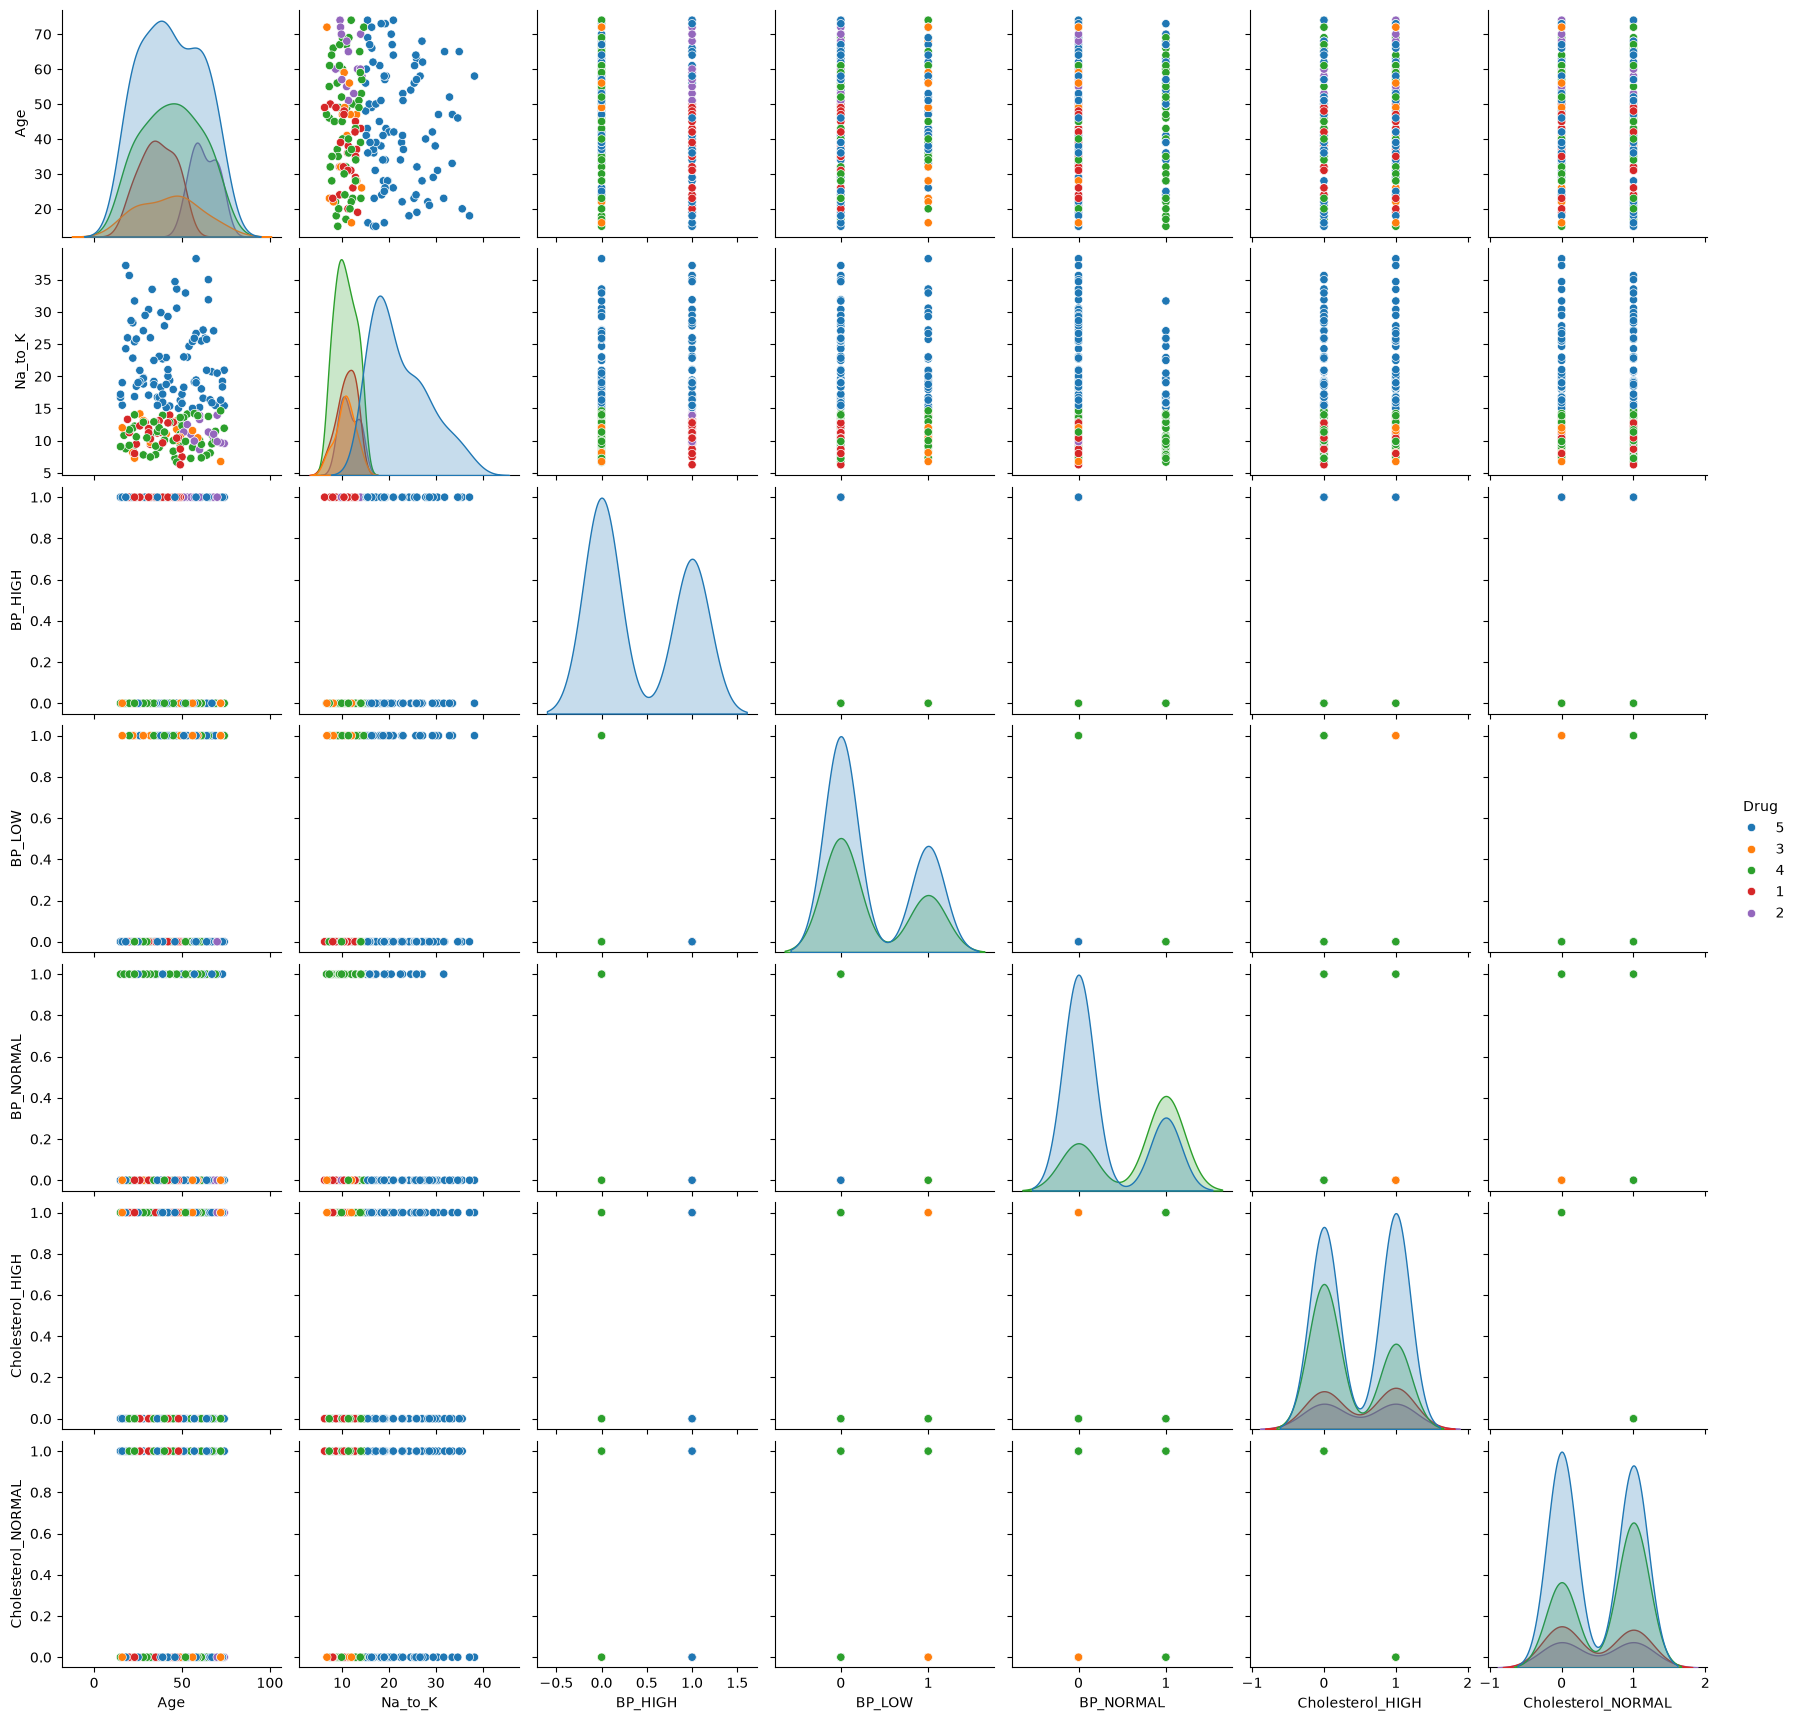

In [66]:
sns.pairplot(df_encode, hue='Drug')
plt.show()

Berdasarkan hasil di atas:
- Fitur umur terhadap semua fitur tidak memiliki perbedaan kelas Drug yang signifikan yakni tercampur
- Fitur Na_to_K terhadap semua fitur label kelas nya hampir tercampur, namun di range 20 hingga 38 memiliki indikasi semua label tersebut adalah DrugY

B7. Menampilkan Heatmap untuk menampilkan korelasi antar data

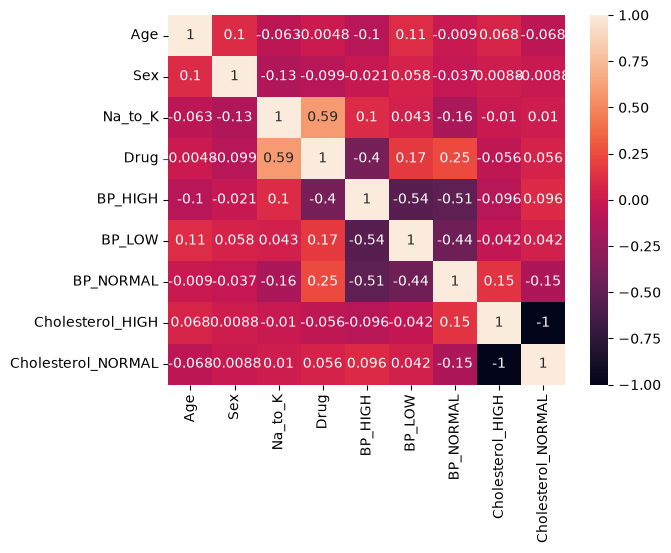

In [67]:
sns.heatmap(df_encode.corr(), annot=True)
plt.show()

Berdasarkan hasil Heatmap di atas:

- Sebagian besar fitur memiliki korelasi yang relatif rendah terhadap kelas Drug. Namun, fitur Na_to_K menunjukkan korelasi positif yang cukup kuat dengan Drug, yaitu sebesar 0,59. Selain itu, fitur BP_NORMAL dan BP_LOW memiliki korelasi masing-masing sebesar 0,25 dan 0,17 terhadap Drug.
- Antarfitur BP hasil One-Hot Encoding memiliki korelasi yang tinggi karena ketiga kolom tersebut berasal dari satu fitur yang sama. Kondisi ini dapat menyebabkan multikolinearitas. Namun, karena kami menggunakan algoritma Decision Tree yang tidak sensitif terhadap multikolinearitas, seluruh kolom tetap dipertahankan tanpa menghapus salah satunya.

## Kesimpulan EDA

Fitur Age memiliki nailai yang cukup beragam, dengan rata-rata umur rentang pada 40-an tahun. Hal ini menunjukan bahwa data mencakup berbagai kelompok usia

Fitur Age memiliki distribusi yang relatif dan tidak menunjukan kemiringan yang signifikan. Sementara itu pada fitur Na_to_K memiliki distribusi data miring ke kanan yang menunjukan bahwa sebagian besar data terkonsentrasi pada nilai yang lebih rendah

Pada pemeriksaan outlier menggunakan metode IQR, ditemukan beberapa nilai ekstrem pada fitur Na_to_K. Namun nilai tersebut tetap kami pertahankan karena kami belum mendapatkan indikasi bahwa nilai tersebut merupakan outlier, Selain itu nilai ekstrem tersebut berpotensi menyimpan informasi yang berguna dalam proses klasifikasi.

Pada visualisasi distribusi data terhadap fitur Drug, fitur Age menunjukan distribusi yang saling bercampuran antarkelas sehingga belum memperlihatkan pola yang jelas. Sebaliknya, fitur Na_to_K menunjukan pola pemisahan kelas yang lebih jelas, terutama pada nilai yang tinggi, yaitu sekitar 20 hingga 38 yang cenderung didominasi oleh kelas DrugY.

Fitur kategorikal seperti BP (Blood Presure) dan Cholesterol menunjukan adanya perbedaan distribusi pada setiap kelas obat. Salah satunya pola yang ditemukan adalah Drug 4 (DrugX) yang cenderung memiliki kategori BP LOW dan NORMAL, sedangkan distribusi Cholesterol mencakup HIGH maupun NORMAL.

Berdasarkan hasil heatmap, Fitur Na_to_K memiliki korelasi positif sebesar 0,59 terhadap label Drug, Sementara itu, fitur BP_NORMAL dan BP_LOW memiliki korelasi masing-masing sebesar 0,25 dan 0,17 terhadap Drug. Hasil One Hot Encoding BP juga memiliki hubungan linear yang tinggi karena berasal satu fitur kategorikal yang sama.

Secara keseluruhan, hasil EDA menunjukan bahwa fitur Na_to_K, BP, dan Cholesterol memiliki pola distribusi yang berpotensi membedakan kelas obat.

# C. Pemodelan

C.1 Split Data Metode Stratified Split Dengan Rasio 80/20

In [68]:
def stratified_split(df, kolom_label):
    daftar_train = []
    daftar_test = []

    labels = df[kolom_label].unique()

    for label in labels:
        label_train = df[df[kolom_label] == label].sample(
            random_state=42, frac=0.8, replace=False
        )

        label_test = df[df[kolom_label] == label].drop(label_train.index)

        daftar_train.append(label_train)
        daftar_test.append(label_test)

    daftar_train = pd.concat(daftar_train)
    daftar_test = pd.concat(daftar_test)

    x_tr = daftar_train.drop(columns=kolom_label)
    y_tr = daftar_train[kolom_label]

    x_te = daftar_test.drop(columns=kolom_label)
    y_te = daftar_test[kolom_label]

    return x_tr.values, y_tr.values, x_te.values, y_te.values

In [69]:
x_tr, y_tr, x_te, y_te = stratified_split(df_encode, kolom_label='Drug')

C.2 Menampilkan Dimensional Data Setelah Split

In [70]:
print(x_tr.shape)
print(y_tr.shape)
print(x_te.shape)
print(y_te.shape)

(160, 8)
(160,)
(40, 8)
(40,)


C.2 Membangun Model Decision Tree

In [71]:
class DecisionTree:

    # Inisialisasi model dengan kedalaman pohon maksimal 5
    def __init__(self, max_depth=5):
        self.tree = None
        self.max_depth = max_depth

    # Mengambil nilai kelas yang paling sering muncul
    def most_common_value(self, arr):
        unique, counts = np.unique(arr, return_counts=True)
        return unique[np.argmax(counts)]

    # Menghitung Gini Impurity untuk mengukur ketidakmurnian kelas
    def gini_impurity(self, y):
        unique, counts = np.unique(y, return_counts=True)
        probs = counts / len(y)
        return 1 - np.sum(probs**2)

    # Menghitung Gini Gain untuk mengetahui kualitas pembagian data
    def gini_gain(self, parent, left, right):
        parent_gini = self.gini_impurity(parent)
        left_gini = self.gini_impurity(left)
        right_gini = self.gini_impurity(right)

        # Menghitung bobot masing-masing cabang berdasarkan jumlah data
        left_weight = len(left) / len(parent)
        right_weight = len(right) / len(parent)

        # Menghitung selisih Gini sebelum dan sesudah pembagian
        return parent_gini - (left_weight * left_gini + right_weight * right_gini)

    # Membangun pohon keputusan secara rekursif
    def build_tree(self, x, y, current_depth):

        # Menghentikan percabangan jika mencapai max_depth atau semua kelas sudah sama
        if current_depth >= self.max_depth or len(np.unique(y)) == 1:
            return self.most_common_value(y)

        # Menyiapkan variabel untuk menyimpan split terbaik
        best_feature = None
        best_split = None
        best_gain = -1

        # Melakukan iterasi pada setiap fitur
        for feature in range(x.shape[1]):

            # Mengambil seluruh nilai unik dari fitur
            unique_values = np.unique(x[:, feature])

            # Mencoba setiap nilai sebagai batas pemisah data
            for values in unique_values:

                # Membagi data menjadi cabang kiri dan kanan
                left_mask = x[:, feature] <= values
                right_mask = x[:, feature] > values

                # Melewati pembagian jika salah satu cabang kosong
                if len(y[left_mask]) == 0 or len(y[right_mask]) == 0:
                    continue

                # Menghitung Gini Gain dari pembagian tersebut
                gain = self.gini_gain(y, y[left_mask], y[right_mask])

                # Menyimpan fitur dan nilai split dengan Gini Gain tertinggi
                if gain > best_gain:
                    best_feature = feature
                    best_split = values
                    best_gain = gain

        # Menghentikan percabangan jika tidak ditemukan split yang valid
        if best_feature is None:
            return self.most_common_value(y)

        # Membagi data berdasarkan fitur dan nilai split terbaik
        left_mask = x[:, best_feature] <= best_split
        right_mask = x[:, best_feature] > best_split

        # Membentuk node dan melanjutkan percabangan ke kiri dan kanan
        return {
            'feature': best_feature,
            'split': best_split,
            'left': self.build_tree(x[left_mask], y[left_mask], current_depth+1),
            'right': self.build_tree(x[right_mask], y[right_mask], current_depth+1)
        }

    # Melatih model dan membangun pohon keputusan dari data training
    def fit(self, x, y):
        self.tree = self.build_tree(x, y, 0)

    # Melakukan prediksi pada satu sampel data
    def predict_sample(self, tree, sample):

        # Jika node bukan dictionary, berarti sudah mencapai leaf node
        if not isinstance(tree, dict):
            return tree

        # Mengambil indeks fitur dan nilai batas pemisah dari node
        feature_index = tree['feature']
        split_value = tree['split']

        # Menentukan cabang berdasarkan nilai fitur pada sampel
        if sample[feature_index] <= split_value:
            return self.predict_sample(tree['left'], sample)
        else:
            return self.predict_sample(tree['right'], sample)

    # Melakukan prediksi pada seluruh sampel data
    def predict(self, x):

        predictions = []

        # Melakukan prediksi satu per satu pada setiap sampel
        for sample in x:
            pred = self.predict_sample(self.tree, sample)
            predictions.append(pred)

        # Mengubah hasil prediksi menjadi array NumPy
        return np.array(predictions)

C.3 Melakukan Grid Search untuk mencari kedalama pohon optimal

In [72]:
def grid_search(depths, x_tr, y_tr, x_te, y_te):
    akurasi_train = []
    akurasi_test = []

    for d in depths:
        model = DecisionTree(d)
        model.fit(x_tr, y_tr)
        y_tr_pred = model.predict(x_tr)
        y_te_pred = model.predict(x_te)

        akurasi_train.append(np.mean(y_tr == y_tr_pred))
        akurasi_test.append(np.mean(y_te == y_te_pred))

        print(f'Depth: {d}✔')

    akurasi_df = pd.DataFrame(data = {'Train': akurasi_train, 'Test': akurasi_test}, index=depths)
    return akurasi_df

In [73]:
akurasi_df = grid_search([1,2,3,4,5,6,7,8,9,10], x_tr, y_tr, x_te, y_te)

Depth: 1✔
Depth: 2✔
Depth: 3✔
Depth: 4✔
Depth: 5✔
Depth: 6✔
Depth: 7✔
Depth: 8✔
Depth: 9✔
Depth: 10✔


C.4 Menampilkan Hasil Akurasi Setiap Kedalaman

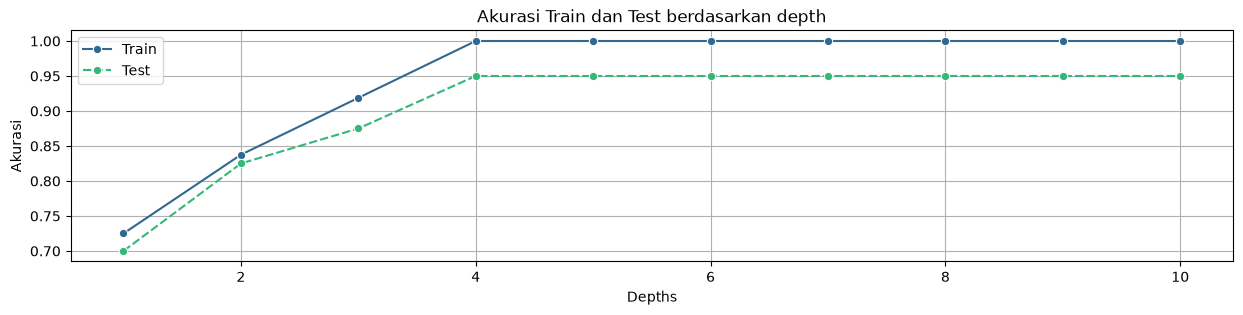

In [74]:
plt.figure(figsize=(15,3))
sns.lineplot(data=akurasi_df, marker='o', palette='viridis')
plt.legend()
plt.grid()
plt.title('Akurasi Train dan Test berdasarkan depth')
plt.xlabel('Depths')
plt.ylabel('Akurasi')
plt.show()

Berdasarkan hasil plot diatas:
- pada kedalaman 1-4 memiliki kenaikan akurasi yang lumayan signifikan
- pada kedalaman 5-10 memiliki kenaikan yang sangat sedikit atau tidak naik sama sekali

C.5 Menampilkan Error akurasi train terhadap test

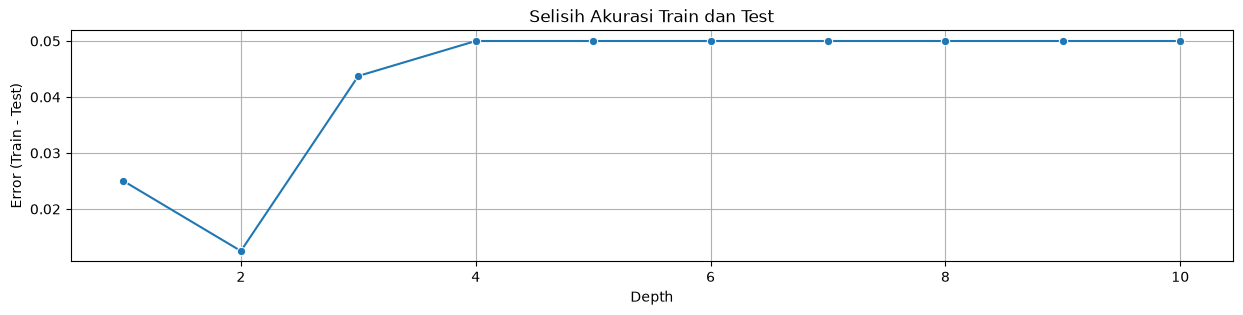

In [75]:
akurasi_df['error'] = akurasi_df['Train'] - akurasi_df['Test']

plt.figure(figsize=(15,3))
sns.lineplot(x=akurasi_df.index, y=akurasi_df['error'], marker='o')
plt.grid()
plt.title('Selisih Akurasi Train dan Test')
plt.xlabel('Depth')
plt.ylabel('Error (Train - Test)')
plt.show()

Berdasarkan hasil diatas, semakin dalam pohon akurasi model akan tetap sama.

Jadi kami memilih untuk menggunakan kedalaman 4, karena kedalaman tidak lebih dari fitur awal (6) sehingga tidak menyebabkan overfitting, dan kompleksitas pohon/percabangan lebih rendah daripada kedalaman 5/6 sehingga membuat komputasi model lebih cepat.

C.6 Melatih model decisiontree menggunakan kedalaman optimal (4)

In [76]:
model = DecisionTree(4)
model.fit(x_tr, y_tr)

C.7 Visualisasi Hasil Pohon

In [77]:
def plot_tree(node,feature_names, x=0.5, y=1, dx=0.25, dy=0.08, ax=None, depth=0, max_depth=4):
    if ax is None:
        fig, ax = plt.subplots(figsize=(20,10))
        ax.axis("off")

    if not isinstance(node, dict):
        ax.text(
            x, y,
            f"Label: {node}",
            ha="center",
            bbox=dict(boxstyle="round", fc="#b3ade6")
        )
        return ax

    if depth >= max_depth:
        ax.text(
            x, y,
            "...",
            ha="center",
            bbox=dict(boxstyle="round", fc="#f46161")
        )
        return ax

    feature = feature_names[node["feature"]]
    split = node["split"]

    label = f"{feature} ≤ {split}"

    ax.text(
        x, y,
        label,
        ha="center",
        bbox=dict(boxstyle="round", fc="#90E0EE")
    )

    ax.plot([x, x-dx], [y, y-dy], 'k-')
    plot_tree(node["left"], feature_names, x-dx, y-dy, dx/2, dy, ax, depth+1, max_depth)

    ax.plot([x,x+dx], [y, y-dy], 'k-')
    plot_tree(node["right"], feature_names, x+dx, y-dy, dx/2, dy, ax, depth+1, max_depth)

    return ax

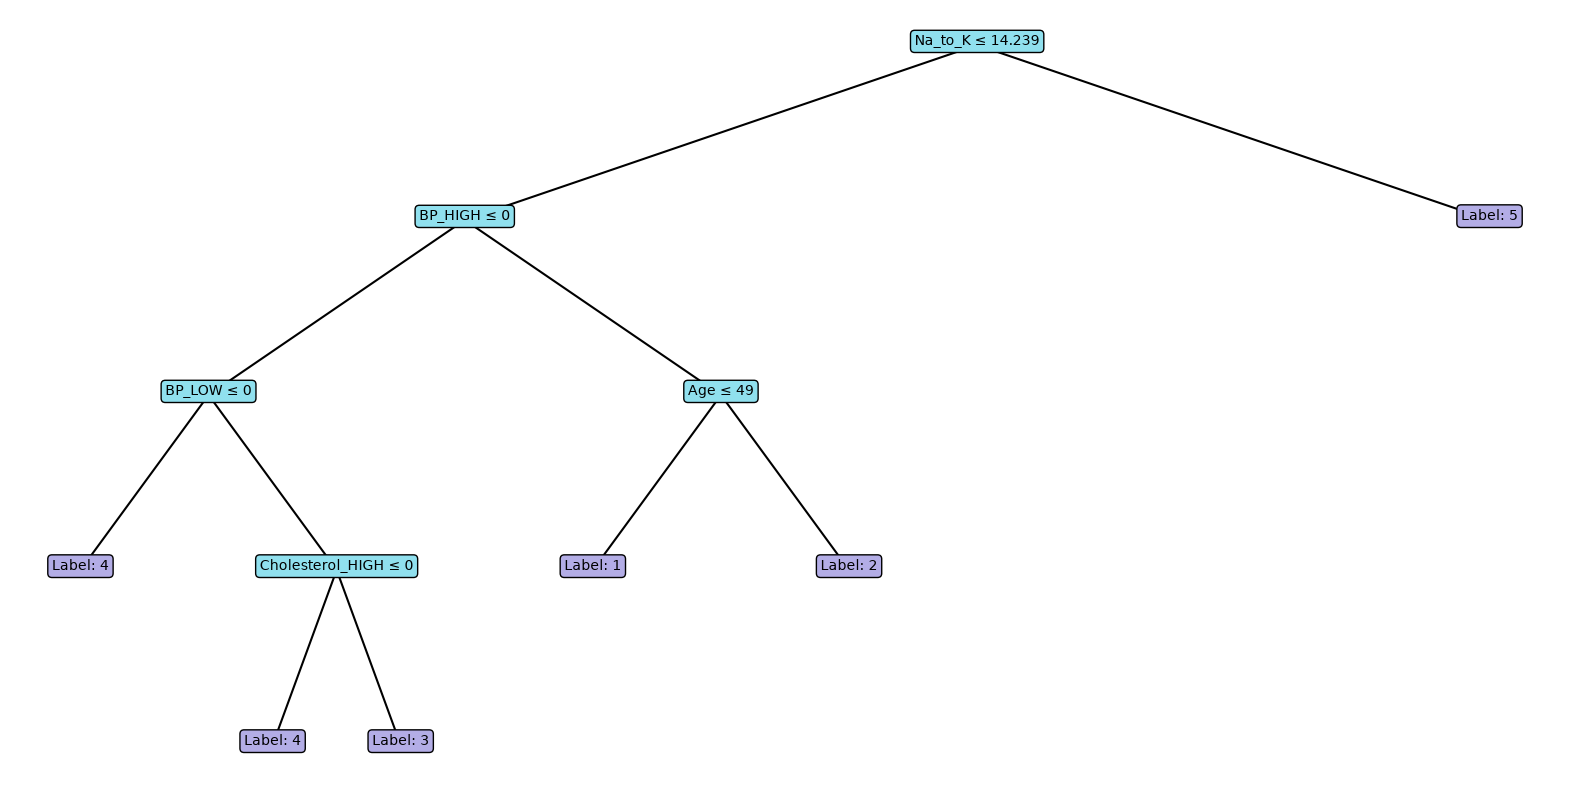

In [78]:
colom = df_encode.drop(columns='Drug').columns
plot_tree(model.tree, colom, max_depth=4)
plt.show() 

Berdasarkan Visualisasi diatas:

- Fitur Na_to_K Merupakan fitur paling berpengaruh karena menjadi root node
- Diikuti dengan BP_High berada pada level selanjutnya menunjukkan Tekanan Darah tinggi juga sangat memengaruhi klasifikasi jenis obat.
- BP_low, Age, dan Cholesterol_high menjadi fitur pemisah lanjutan untuk membantu proses klasifikasi jenis obat

C.8 Prediksi Label dari data train dan test menggunakan Model Decision Tree

In [82]:
y_pred_te = model.predict(x_te)
y_pred_tr = model.predict(x_tr)

# E. Evaluasi

E.1 Fungsi Confussion Matrix dan Metrik Evaluasi

In [102]:
labels = {
    '1': 'DrugA',
    '2': 'DrugB',
    '3': 'DrugC',
    '4': 'DrugX',
    '5': 'DrugY'
}
def evaluasi_model(y,y_pred):
    lbl = np.unique(np.concatenate((y,y_pred)))
    cm = pd.DataFrame(np.zeros([len(lbl), len(lbl)]), columns=lbl, index=lbl, dtype=int)

    for a,p in zip(y,y_pred):
        cm.loc[a,p] += 1

    print(f'Akurasi : {np.mean(y == y_pred)*100:.2f}%')

    for l in lbl:
        tp = cm.loc[l,l]
        fp = cm[l].sum() - tp
        fn = cm.loc[l].sum() - tp

        presisi = tp / (tp + fp) if (tp + fp) != 0 else 0
        recall = tp / (tp + fn) if (tp + fn) != 0 else 0
        f1_score = (presisi+recall) /2

        nama_label = [labels[str(l)] for l in lbl]
        print(f'------- {labels[l]}')
        print(f'Presisi  : {presisi:.5f}')
        print(f'Recall   : {recall:.5f}')
        print(f'F1 Score : {f1_score:.5f}')

    sns.heatmap(data=cm, fmt='d', annot=True, cmap='Blues', xticklabels=nama_label, yticklabels=nama_label)
    plt.xlabel('Predict')
    plt.ylabel('Actual')
    plt.show()

E.2 Menampilkan Evaluasi Untuk Data Train

Akurasi : 100.00%
------- DrugA
Presisi  : 1.00000
Recall   : 1.00000
F1 Score : 1.00000
------- DrugB
Presisi  : 1.00000
Recall   : 1.00000
F1 Score : 1.00000
------- DrugC
Presisi  : 1.00000
Recall   : 1.00000
F1 Score : 1.00000
------- DrugX
Presisi  : 1.00000
Recall   : 1.00000
F1 Score : 1.00000
------- DrugY
Presisi  : 1.00000
Recall   : 1.00000
F1 Score : 1.00000


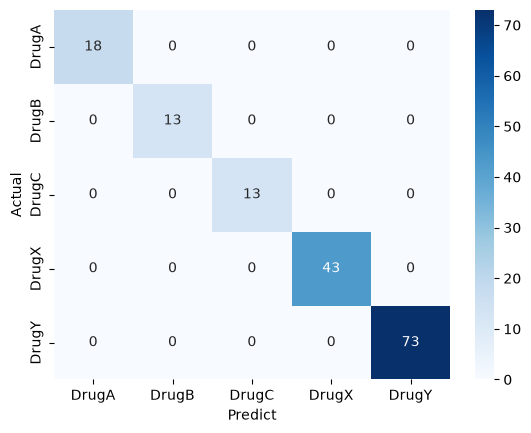

In [103]:
evaluasi_model(y_pred_tr, y_tr)

E.2 Menampilkan Metrik Evaluasi Untuk Data Test

Akurasi : 95.00%
------- DrugA
Presisi  : 1.00000
Recall   : 0.80000
F1 Score : 0.90000
------- DrugB
Presisi  : 0.75000
Recall   : 1.00000
F1 Score : 0.87500
------- DrugC
Presisi  : 1.00000
Recall   : 1.00000
F1 Score : 1.00000
------- DrugX
Presisi  : 1.00000
Recall   : 0.90909
F1 Score : 0.95455
------- DrugY
Presisi  : 0.94737
Recall   : 1.00000
F1 Score : 0.97368


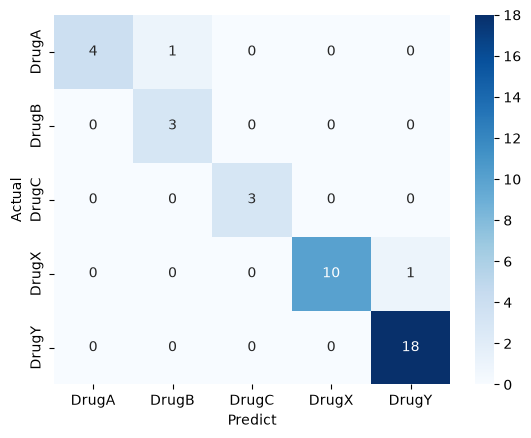

In [104]:
evaluasi_model(y_te, y_pred_te)

### **KESIMPULAN**

- Proses klasifikasi menggunakan algoritma Decision Tree berhasil memprediksi jenis obat berdasarkan fitur Age, Sex, BP, Cholesterol, dan Na_to_K. Hal ini menunjukkan bahwa fitur-fitur tersebut dapat digunakan untuk membedakan jenis obat berdasarkan karakteristik pasien.

- Hasil evaluasi menunjukkan bahwa model memperoleh akurasi sebesar 100% pada data training dan 95% pada data testing. Hal ini menunjukkan bahwa model memiliki kemampuan klasifikasi yang baik, meskipun terdapat selisih akurasi yang mengindikasikan adanya overfitting.

- Berdasarkan evaluasi setiap kelas, DrugC memperoleh performa terbaik dengan nilai Precision, Recall, dan F1-Score sebesar 100%. Sementara itu, DrugB memiliki nilai Precision terendah sebesar 75%, yang menunjukkan masih terdapat kesalahan dalam memprediksi kelas tersebut.

- Secara keseluruhan, algoritma Decision Tree mampu mengklasifikasikan jenis obat dengan performa yang baik, ditunjukkan oleh akurasi testing sebesar 95% serta nilai Precision, Recall, dan F1-Score yang tinggi pada sebagian besar kelas.

# E. Graphical User Interface

E.1 Import Library Tambahan

In [136]:
from tkinter import *
from tkinter import ttk, messagebox

E.2 Kode Utama GUI

In [139]:
window = Tk()
window.title('Drug Prediction')
window.configure(bg='Teal')
window.geometry('500x430')

def submit():
    try:
        age = float(entryage.get())
        na = float(entryna.get())

        gender = gender_i.get()
        bp = bp_i.get()
        chol = cholesterol_i.get()

        if gender == '' or bp == '' or chol == '':
            raise ValueError

        if age <= 0 or na <= 0:
            raise ValueError

    except ValueError:
        messagebox.showerror('Error', 'Periksa kembali input data!')
        return

    # Encoding fitur kategorikal
    sex = 1 if gender == 'M' else 2

    bp_encode = {
        'HIGH': [1, 0, 0],
        'LOW': [0, 1, 0],
        'NORMAL': [0, 0, 1]
    }

    chol_encode = {
        'HIGH': [1, 0],
        'NORMAL': [0, 1]
    }

    bp_value = bp_encode[bp]
    chol_value = chol_encode[chol]

    x_baru = [[
        age, sex, na,
        *bp_value,
        *chol_value
    ]]

    y_pred = model.predict(x_baru)[0]

    labels = {
        '1': 'DrugA',
        '2': 'DrugB',
        '3': 'DrugC',
        '4': 'DrugX',
        '5': 'DrugY'
    }

    hasil = labels.get(str(y_pred), str(y_pred))

    messagebox.showinfo('Hasil Prediksi', f'Obat yang direkomendasikan: {hasil}')


label1 = Label(window, text='Drug Prediction', font=('Arial', 17, 'bold'), bg='Teal', fg='white')
label1.pack(pady=15)

frame1 = Frame(window, bg='Teal')
frame1.pack(pady=10)

Label(frame1, text='Age:', bg='Teal', fg='white').grid(row=0, column=0, padx=10, pady=8)
entryage = Entry(frame1)
entryage.grid(row=0, column=1)

Label(frame1, text='Gender:', bg='Teal', fg='white').grid(row=1, column=0, padx=10, pady=8)
gender_i = ttk.Combobox(frame1, values=['M', 'F'], state='readonly')
gender_i.grid(row=1, column=1)

Label(frame1, text='Na_to_K:', bg='Teal', fg='white').grid(row=2, column=0, padx=10, pady=8)
entryna = Entry(frame1)
entryna.grid(row=2, column=1)

Label(frame1, text='Blood Pressure:', bg='Teal', fg='white').grid(row=3, column=0, padx=10, pady=8)
bp_i = ttk.Combobox(frame1, values=['HIGH', 'LOW', 'NORMAL'], state='readonly')
bp_i.grid(row=3, column=1)

Label(frame1, text='Cholesterol:', bg='Teal', fg='white').grid(row=4, column=0, padx=10, pady=8)
cholesterol_i = ttk.Combobox(frame1, values=['HIGH', 'NORMAL'], state='readonly')
cholesterol_i.grid(row=4, column=1)

sbmt = Button(window, text='Predict', relief=FLAT, background='orange', font=('Arial', 14, 'bold'), command=submit)
sbmt.pack(pady=20)

window.mainloop()